# Retail Sales Analytics & B2B Classification

**Project type:** Data Analytics + Exploratory Data Science  
**Dataset:** `Excel Project Dataset - pandas.xlsx`

This notebook explores retail order data, prepares it for analysis, creates business-focused visualizations, and tests whether order characteristics can help distinguish B2B from B2C transactions.

> **Important:** The uploaded notebook references a different workbook (`Vrinda Store Data Analysis - Copy.xlsx`). This revised notebook uses the repository filename requested for this project. Confirm that the Excel workbook has the expected columns before running all cells.

## 1. Project objectives

### Data Analytics
- Inspect data quality, missing values, duplicates, and data types.
- Standardize column names and prepare useful date and quantity features.
- Analyze sales, order status, product categories, sales channels, customer age groups, and geographic performance.
- Translate charts into measurable business observations.

### Data Science
- Explore a binary classification task: predict whether an order is B2B or B2C.
- Compare a simple baseline with a class-weighted Random Forest.
- Evaluate the model with precision, recall, F1-score, confusion matrix, and average precision (PR-AUC).

The B2B target is highly imbalanced in the original notebook. Therefore, accuracy alone is not an acceptable measure of model quality.

## 2. Setup and imports

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    precision_recall_fscore_support,
    average_precision_score,
    balanced_accuracy_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
DATA_PATH = Path("Excel Project Dataset - pandas.xlsx")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

## 3. Load the Excel dataset

In [7]:
df = pd.read_excel("./Vrinda Store Data Analysis - Copy.xlsx")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]:,}")
display(df.head())

Rows: 31,047 | Columns: 19


,index,Order ID,Cust ID,Gender,Age,Date,Status,Channel,SKU,Category,Size,Qty,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,B2B
0,1,171-1029312-3038738,1029312,Women,44,2022-12-04,Delivered,Myntra,JNE1233-BLUE-KR-031-XXL,kurta,XXL,1,INR,376,MOHALI,PUNJAB,140301,IN,False
1,2,405-2183842-2225946,2183842,Women,29,2022-12-04,Delivered,Ajio,SET414-KR-NP-L,Set,L,1,INR,1449,GURUGRAM,HARYANA,122002,IN,False
2,3,171-1641533-8921966,1641533,Women,67,2022-12-04,Delivered,Myntra,SET261-KR-PP-S,Set,S,1,INR,453,KOLKATA,WEST BENGAL,700029,IN,False
3,4,404-7490807-6300351,7490807,Women,20,2022-12-04,Delivered,Amazon,SET110-KR-PP-M,Set,M,1,INR,729,THANJAVUR,TAMIL NADU,613007,IN,False
4,5,403-9293516-4577154,9293516,Women,62,2022-12-04,Delivered,Myntra,JNE2294-KR-A-XXL,kurta,XXL,1,INR,544,GURUGRAM,HARYANA,122001,IN,False


## 4. Data understanding and quality checks

The original workbook appears to contain order-level fields such as `Order ID`, `Cust ID`, `Gender`, `Age`, `Date`, `Status`, `Category`, `Size`, `Qty`, `Amount`, shipping geography, `B2B`, and sales channel.

The following cell standardizes headers so small differences such as `Channel ` versus `Channel` do not break the analysis.

In [8]:
# Normalize column labels: trim whitespace, collapse internal spaces.
df.columns = (
    df.columns.astype(str)
      .str.strip()
      .str.replace(r"\\s+", " ", regex=True)
)

# Some source exports may contain a trailing space in "Channel".
# Header normalization above handles that without creating duplicate columns.
print("Columns:")
print(df.columns.tolist())

display(df.info())
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_values"))
display(df.describe(include="all").T)

Columns:
['index', 'Order ID', 'Cust ID', 'Gender', 'Age', 'Date', 'Status', 'Channel', 'SKU', 'Category', 'Size', 'Qty', 'currency', 'Amount', 'ship-city', 'ship-state', 'ship-postal-code', 'ship-country', 'B2B']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31047 entries, 0 to 31046
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   index             31047 non-null  int64         
 1   Order ID          31047 non-null  object        
 2   Cust ID           31047 non-null  int64         
 3   Gender            31047 non-null  object        
 4   Age               31047 non-null  int64         
 5   Date              31047 non-null  datetime64[ns]
 6   Status            31047 non-null  object        
 7   Channel           31047 non-null  object        
 8   SKU               31047 non-null  object        
 9   Category          31047 non-null  object        
 10  Size              31047 

None

,missing_values
index,0
Order ID,0
Cust ID,0
Gender,0
Age,0
Date,0
Status,0
Channel,0
SKU,0
Category,0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
index,"31,047.00",NaN,NaN,NaN,"15,524.00",1.00,"7,762.50","15,524.00","23,285.50","31,047.00","8,962.64"
Order ID,31047,28471,403-4984515-8861958,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cust ID,"31,047.00",NaN,NaN,NaN,"4,936,823.83",895.00,"2,416,471.00","4,909,885.00","7,454,181.50","9,999,233.00","2,900,677.95"
Gender,31047,4,Women,21479,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,"31,047.00",NaN,NaN,NaN,39.50,18.00,28.00,37.00,47.00,78.00,15.12
Date,31047,NaN,NaN,NaN,2022-06-15 06:41:39.719779584,2022-01-04 00:00:00,2022-03-06 00:00:00,2022-06-06 00:00:00,2022-09-06 00:00:00,2022-12-06 00:00:00,NaN
Status,31047,4,Delivered,28641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Channel,31047,7,Amazon,11016,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SKU,31047,5287,JNE3797-KR-L,273,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,31047,8,Set,12391,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Data cleaning and feature engineering

In [9]:
data = df.copy()

# Convert common numeric fields safely.
for col in ["Age", "Amount", "Qty", "Quantity", "ship-postal-code"]:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")

# Standardize quantity field.
if "Qty" in data.columns and "Quantity" not in data.columns:
    data = data.rename(columns={"Qty": "Quantity"})

if "Quantity" in data.columns:
    quantity_map = {
        "one": 1, "two": 2, "three": 3, "four": 4, "five": 5
    }
    data["Quantity"] = data["Quantity"].apply(
        lambda value: quantity_map.get(value.strip().lower(), value)
        if isinstance(value, str) else value
    )
    data["Quantity"] = pd.to_numeric(data["Quantity"], errors="coerce")

# Parse dates.
if "Date" in data.columns:
    data["Date"] = pd.to_datetime(data["Date"], errors="coerce", dayfirst=False)

# Normalize common categorical values.
for col in ["Gender", "Status", "Category", "Size", "Channel",
            "ship-city", "ship-state"]:
    if col in data.columns:
        data[col] = data[col].astype("string").str.strip()

if "Gender" in data.columns:
    data["Gender"] = data["Gender"].replace({"M": "Men", "W": "Women"})

# Convert B2B to a consistent binary target where possible.
if "B2B" in data.columns:
    if data["B2B"].dtype == "object" or str(data["B2B"].dtype).startswith("string"):
        b2b_map = {
            "true": 1, "false": 0, "yes": 1, "no": 0,
            "1": 1, "0": 0
        }
        data["B2B"] = data["B2B"].astype("string").str.strip().str.lower().map(b2b_map)
    else:
        data["B2B"] = pd.to_numeric(data["B2B"], errors="coerce")

# Add date features.
if "Date" in data.columns:
    data["Year"] = data["Date"].dt.year
    data["Month"] = data["Date"].dt.month
    data["DayOfWeek"] = data["Date"].dt.day_name()

# Create transparent age bands. These are descriptive bands, not demographic claims.
if "Age" in data.columns:
    data["Age Group"] = pd.cut(
        data["Age"],
        bins=[0, 17, 34, 54, np.inf],
        labels=["17 or younger", "18–34", "35–54", "55+"],
        include_lowest=True
    )

# Keep the original rows: repeated Order IDs may represent multiple line items.
print("Repeated Order IDs:", data["Order ID"].duplicated().sum()
      if "Order ID" in data.columns else "Order ID not available")
display(data.head())

Repeated Order IDs: 2576


,index,Order ID,Cust ID,Gender,Age,Date,Status,Channel,SKU,Category,Size,Quantity,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,B2B,Year,Month,DayOfWeek,Age Group
0,1,171-1029312-3038738,1029312,Women,44,2022-12-04,Delivered,Myntra,JNE1233-BLUE-KR-031-XXL,kurta,XXL,1.00,INR,376,MOHALI,PUNJAB,140301,IN,False,2022,12,Sunday,35–54
1,2,405-2183842-2225946,2183842,Women,29,2022-12-04,Delivered,Ajio,SET414-KR-NP-L,Set,L,1.00,INR,1449,GURUGRAM,HARYANA,122002,IN,False,2022,12,Sunday,18–34
2,3,171-1641533-8921966,1641533,Women,67,2022-12-04,Delivered,Myntra,SET261-KR-PP-S,Set,S,1.00,INR,453,KOLKATA,WEST BENGAL,700029,IN,False,2022,12,Sunday,55+
3,4,404-7490807-6300351,7490807,Women,20,2022-12-04,Delivered,Amazon,SET110-KR-PP-M,Set,M,1.00,INR,729,THANJAVUR,TAMIL NADU,613007,IN,False,2022,12,Sunday,18–34
4,5,403-9293516-4577154,9293516,Women,62,2022-12-04,Delivered,Myntra,JNE2294-KR-A-XXL,kurta,XXL,1.00,INR,544,GURUGRAM,HARYANA,122001,IN,False,2022,12,Sunday,55+


### Duplicate interpretation

A repeated `Order ID` is not automatically a duplicate row. Retail exports commonly store one row per item or product line, so an order can legitimately appear more than once. Investigate repeated rows across all columns before removing anything.

In [10]:
# Exact duplicate rows are safer to inspect separately from repeated order IDs.
exact_duplicates = data.duplicated().sum()
print(f"Exact duplicate rows: {exact_duplicates:,}")

if exact_duplicates:
    display(data.loc[data.duplicated(keep=False)].head(10))

Exact duplicate rows: 0


## 6. Exploratory Data Analysis (EDA)

In [12]:
# Define a reusable chart helper.
def bar_chart(series, title, xlabel="", ylabel="Count", top_n=None, figsize=(10, 5)):
    values = series
    if top_n is not None:
        values = values.head(top_n)
    ax = values.plot(kind="bar", figsize=figsize)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

### 6.1 Key sales KPIs

In [13]:
required_for_kpis = {"Amount"}
if required_for_kpis.issubset(data.columns):
    print(f"Total recorded sales amount: {data['Amount'].sum():,.2f}")
    print(f"Average line-item amount: {data['Amount'].mean():,.2f}")
    print(f"Median line-item amount: {data['Amount'].median():,.2f}")

if "Order ID" in data.columns:
    print(f"Unique orders: {data['Order ID'].nunique():,}")
if "Cust ID" in data.columns:
    print(f"Unique customers: {data['Cust ID'].nunique():,}")
if "Quantity" in data.columns:
    print(f"Total units: {data['Quantity'].sum():,.0f}")

Total recorded sales amount: 21,176,377.00
Average line-item amount: 682.07
Median line-item amount: 646.00
Unique orders: 28,471
Unique customers: 28,437
Total units: 31,192


### 6.2 Sales by gender and channel

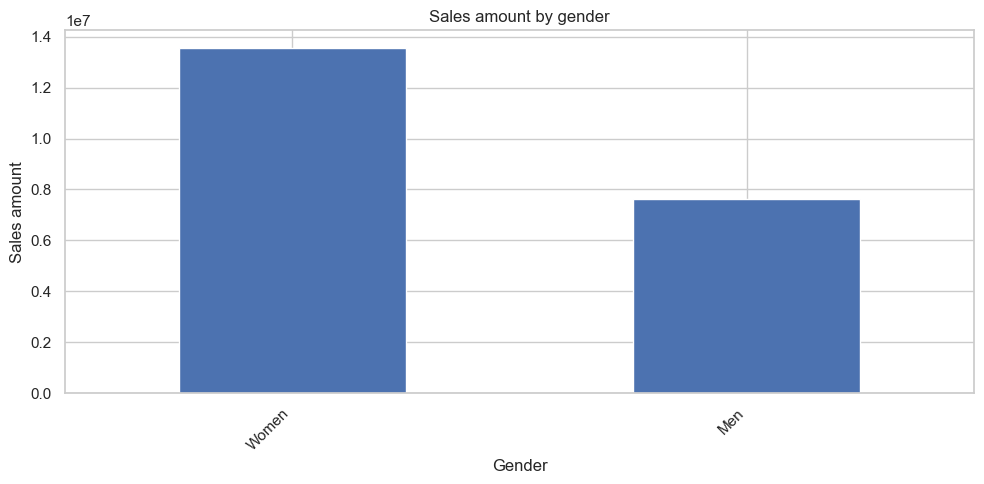

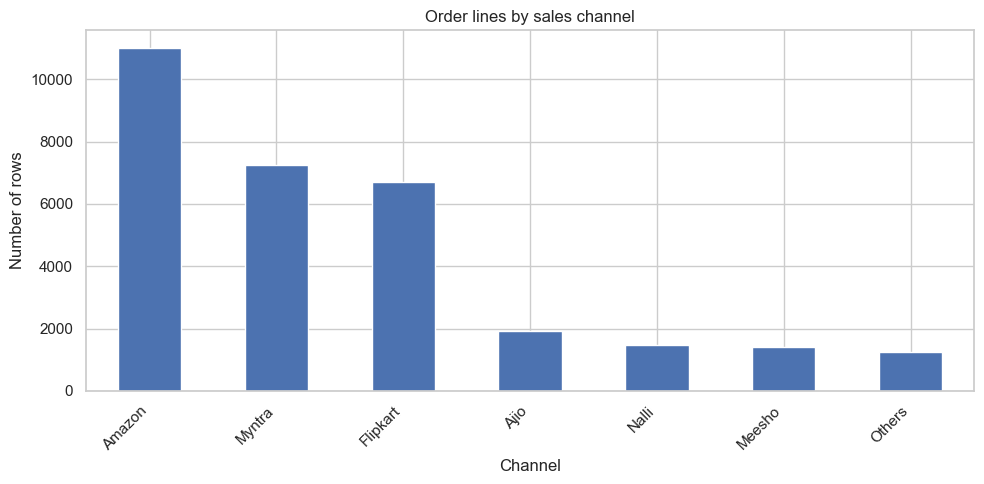

In [14]:
if {"Gender", "Amount"}.issubset(data.columns):
    gender_sales = data.groupby("Gender", dropna=False)["Amount"].sum().sort_values(ascending=False)
    bar_chart(gender_sales, "Sales amount by gender", "Gender", "Sales amount")

if "Channel" in data.columns:
    channel_orders = data["Channel"].value_counts(dropna=False)
    bar_chart(channel_orders, "Order lines by sales channel", "Channel", "Number of rows")

### 6.3 Monthly sales trend

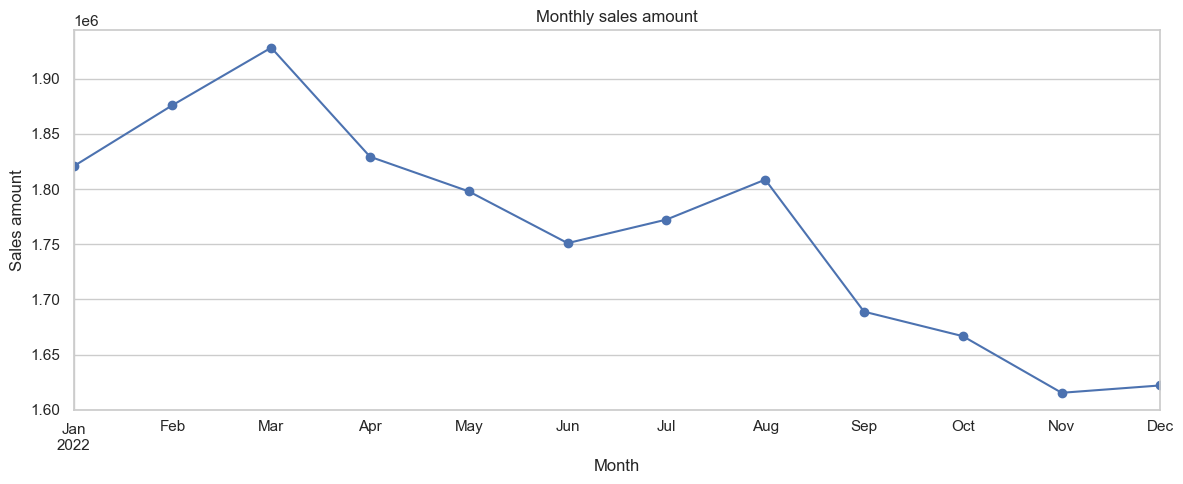

In [15]:
if {"Date", "Amount"}.issubset(data.columns):
    monthly_sales = (
        data.dropna(subset=["Date"])
            .set_index("Date")["Amount"]
            .resample("MS").sum()
    )
    ax = monthly_sales.plot(figsize=(12, 5), marker="o")
    ax.set_title("Monthly sales amount")
    ax.set_xlabel("Month")
    ax.set_ylabel("Sales amount")
    plt.tight_layout()
    plt.show()

### 6.4 Product category and order status

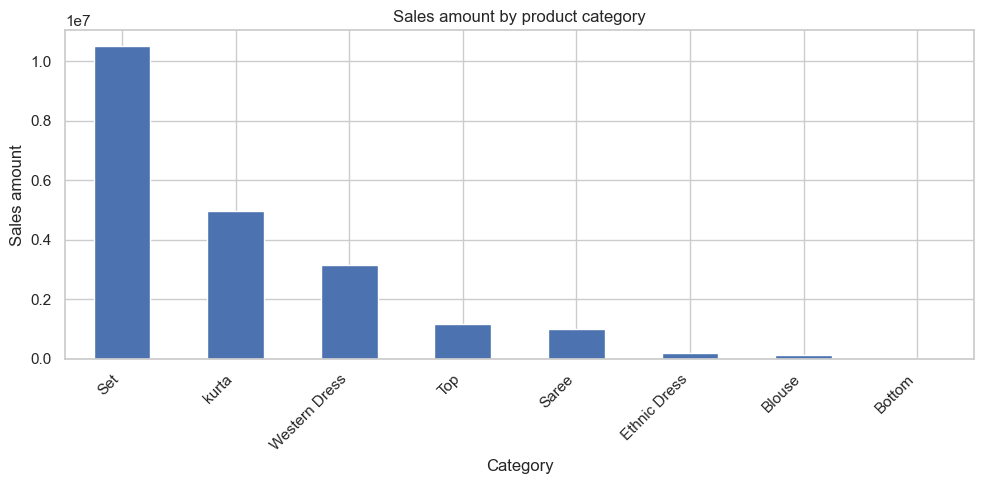

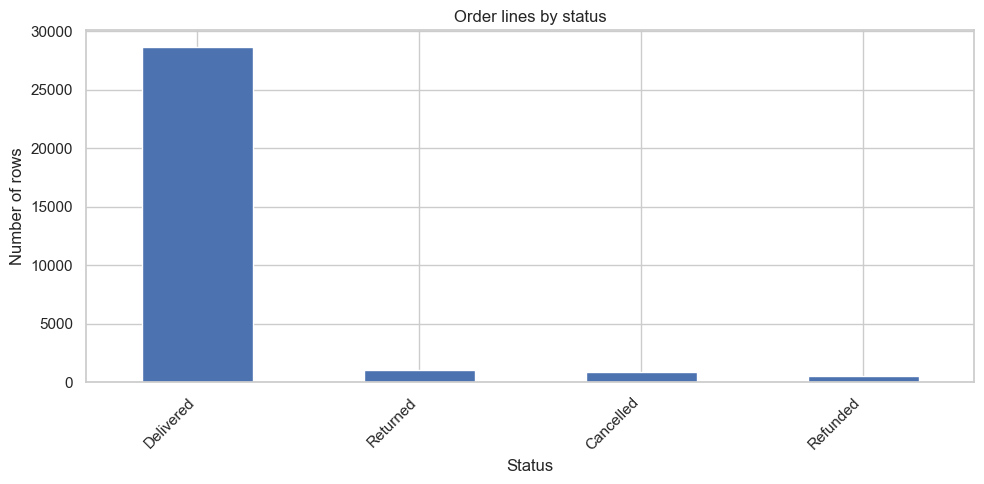

In [16]:
if "Category" in data.columns:
    category_sales = data.groupby("Category", dropna=False)["Amount"].sum().sort_values(ascending=False) if "Amount" in data.columns else data["Category"].value_counts()
    bar_chart(category_sales, "Sales amount by product category" if "Amount" in data.columns else "Rows by product category",
              "Category", "Sales amount" if "Amount" in data.columns else "Rows", top_n=15)

if "Status" in data.columns:
    status_counts = data["Status"].value_counts(dropna=False)
    bar_chart(status_counts, "Order lines by status", "Status", "Number of rows")

### 6.5 Geographic sales performance

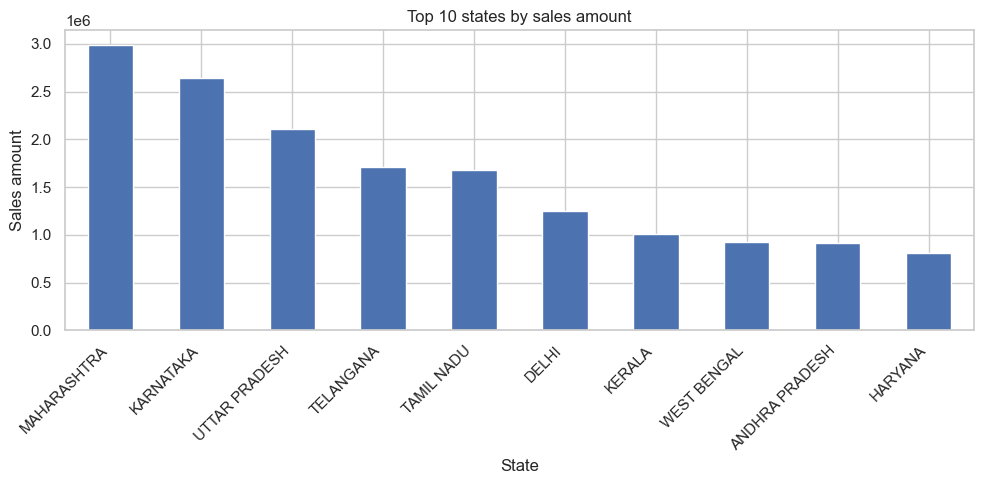

In [17]:
if {"ship-state", "Amount"}.issubset(data.columns):
    state_sales = data.groupby("ship-state")["Amount"].sum().sort_values(ascending=False)
    bar_chart(state_sales, "Top 10 states by sales amount", "State", "Sales amount", top_n=10)

### 6.6 Customer age groups

The age bands below are descriptive categories used for exploratory analysis. Interpret them alongside sample sizes and avoid treating them as causal explanations.

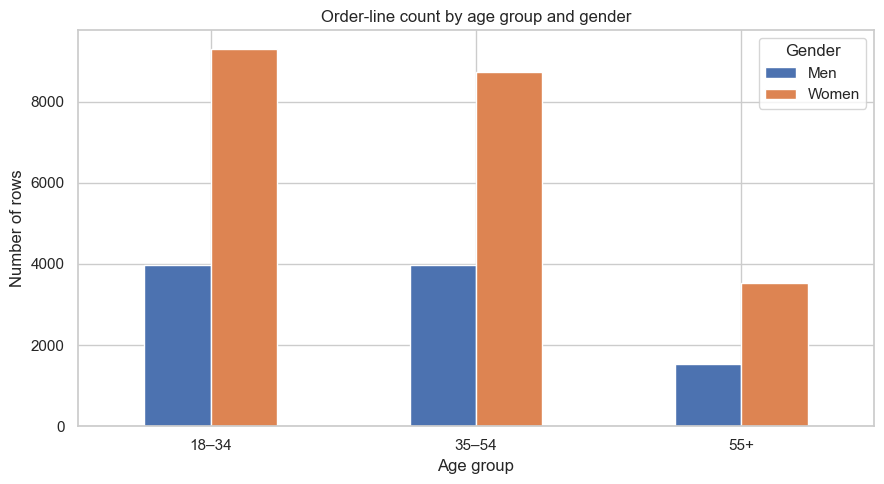

In [18]:
if {"Age Group", "Gender"}.issubset(data.columns):
    age_gender = pd.crosstab(data["Age Group"], data["Gender"])
    ax = age_gender.plot(kind="bar", figsize=(9, 5))
    ax.set_title("Order-line count by age group and gender")
    ax.set_xlabel("Age group")
    ax.set_ylabel("Number of rows")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

## 7. Business insights: write evidence-based findings

Use the charts and KPI outputs to write 3–5 concise observations. Do not insert generic claims. Each finding should cite a metric from your actual run, explain its business relevance, and distinguish correlation from causation.

Suggested format:
- **Observation:** [what the data shows]
- **Evidence:** [metric / percentage / period]
- **Business implication:** [what a retail team could investigate or improve]

## 8. Predictive modeling: B2B vs B2C classification

**Target:** `B2B`  
**Task:** binary classification  
**Model:** class-weighted Random Forest  
**Baseline:** most-frequent Dummy Classifier

This is an exploratory modeling exercise. Before interpreting results, confirm that all selected features would be available at the intended prediction time. For example, `Status` may be known only after an order has progressed, so it may be inappropriate for an early-order prediction use case.

In [19]:
target = "B2B"
if target not in data.columns:
    raise KeyError("The B2B target column is missing. Check the workbook schema.")

model_data = data.loc[data[target].notna()].copy()
y = model_data[target].astype(int)

class_counts = y.value_counts().sort_index()
display(class_counts.to_frame("count"))
print("Class proportions:")
display(y.value_counts(normalize=True).rename("proportion").to_frame())

if y.nunique() != 2:
    raise ValueError(f"Expected a binary B2B target, found classes: {sorted(y.unique())}")

# Exclude identifiers, raw date, target, and high-cardinality postal code.
# Keep only features that make sense for the intended prediction point.
excluded = {
    target, "Order ID", "Cust ID", "Date",
    "ship-postal-code", "index", "SKU", "currency"
}
feature_cols = [col for col in model_data.columns if col not in excluded]

X = model_data[feature_cols].copy()

# Remove columns that are entirely empty.
X = X.dropna(axis=1, how="all")

# Split before fitting any learned preprocessing.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=400,
        class_weight="balanced_subsample",
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)
y_pred = rf_pipeline.predict(X_test)
y_score = rf_pipeline.predict_proba(X_test)[:, 1]

,count
B2B,
0,30861
1,186


Class proportions:


,proportion
B2B,
0,0.99
1,0.01


## 9. Model evaluation

Baseline (most frequent class)
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      6173
           1       0.00      0.00      0.00        37

    accuracy                           0.99      6210
   macro avg       0.50      0.50      0.50      6210
weighted avg       0.99      0.99      0.99      6210

Baseline balanced accuracy: 0.5
\nRandom Forest
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      6173
           1       0.31      0.11      0.16        37

    accuracy                           0.99      6210
   macro avg       0.65      0.55      0.58      6210
weighted avg       0.99      0.99      0.99      6210

Random Forest balanced accuracy: 0.5533250730075613
Random Forest average precision (PR-AUC): 0.0804573364284695


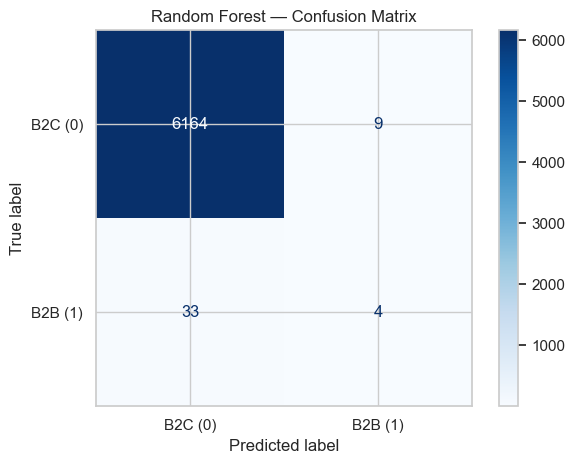

In [20]:
print("Baseline (most frequent class)")
print(classification_report(y_test, baseline_pred, zero_division=0))
print("Baseline balanced accuracy:", balanced_accuracy_score(y_test, baseline_pred))

print("\\nRandom Forest")
print(classification_report(y_test, y_pred, zero_division=0))
print("Random Forest balanced accuracy:", balanced_accuracy_score(y_test, y_pred))
print("Random Forest average precision (PR-AUC):", average_precision_score(y_test, y_score))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["B2C (0)", "B2B (1)"],
    cmap="Blues",
    values_format="d"
)
plt.title("Random Forest — Confusion Matrix")
plt.tight_layout()
plt.show()

### How to interpret the model

- **Precision (B2B):** among orders predicted as B2B, how many were actually B2B?
- **Recall (B2B):** among actual B2B orders, how many did the model identify?
- **F1-score:** balance between precision and recall.
- **Average precision:** summarizes the precision-recall curve and is useful when the positive class is rare.
- **Balanced accuracy:** averages recall across the two classes.

Compare these metrics with the baseline. If positive-class recall or precision remains weak, report that honestly and treat the model as a baseline requiring further work. Do not claim success from accuracy alone.

## 10. Limitations and next steps

1. Validate the workbook's exact schema and business definitions.
2. Confirm whether each row is an order, an order line, or a product line before aggregating revenue or counting orders.
3. Check whether `Amount` is item value, order value, or net sales; the notebook uses the field as supplied.
4. Decide the prediction moment and remove features unavailable at that moment.
5. Tune the decision threshold using validation data if the business objective requires higher B2B recall or precision.
6. Consider time-based validation if the goal is to predict future orders.
7. Add SHAP or permutation importance only after the evaluation design is sound.
8. Add a Power BI dashboard for an interactive business-facing view.

## 11. Reproducibility

Run the notebook from the repository root after installing the dependencies in `requirements.txt`. Keep the Excel workbook in the same folder as this notebook, or update `DATA_PATH`.